# 迭代优化的基本工具

In [1]:
from pathlib import Path
import sys
root = Path.cwd().resolve()
while not (root / 'lsq').is_dir():
    if root == root.parent:
        raise RuntimeError('Run inside the repository')
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
from lsq import (finite_difference, whiten, gauss_newton,
                 levenberg_marquardt, dogleg, recursive_update)
np.set_printoptions(precision=5, suppress=True)
plt.rcParams.update({'figure.figsize': (6.4, 3.3), 'font.size': 10,
                     'axes.grid': True, 'savefig.dpi': 130})

在非线性问题中，“方向大致正确”和“步子足够谨慎”是两项独立任务。先理解这两件事，后面的GN、LM和信赖域就不再只是公式名称。

## 下降方向和步长

对于可微目标$F$，若$g^Th<0$，则沿$h$走足够小的正步长会下降。最速下降取$h=-g$；它在欧氏单位球内给出最大的局部线性下降，但不代表整个优化过程最快。

Armijo回溯从$\alpha=1$开始，若

$$F(x+\alpha h)\le F(x)+c\alpha g^Th,\qquad 0<c<1,$$

不成立，就缩小$\alpha$。这里右侧比当前目标更低，要求下降量与局部预测有合理联系。实现时还必须限制回溯次数或最小步长。

## 为什么最速下降会来回摆动

对二次目标$F(x)=\tfrac12x^TBx$，若$B$的特征值差别很大，等高线狭长，负梯度容易横穿“山谷”。固定步长稳定性要求$0<\alpha<2/\lambda_{\max}(B)$。沿曲率大的方向稳定的步长，在曲率小的方向就显得很慢。

gradient method final norm: 2.0236746917870024e-06


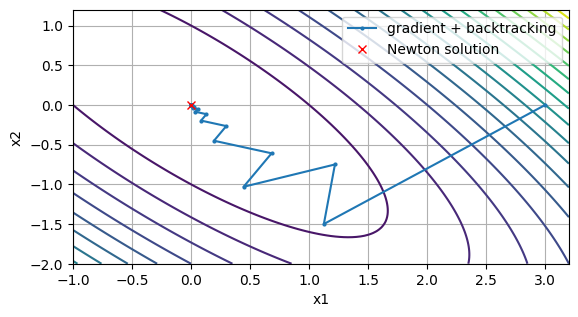

In [2]:
B = np.array([[10., 8.], [8., 10.]])
cost = lambda x: .5*x@B@x
x = np.array([3., 0.]); path = [x.copy()]
for _ in range(35):
    g = B@x; h = -g; alpha = 1.
    while cost(x+alpha*h) > cost(x)+1e-4*alpha*(g@h):
        alpha *= .5
    x = x+alpha*h
    path.append(x.copy())
path = np.array(path)
u, v = np.meshgrid(np.linspace(-1, 3.2, 120), np.linspace(-2, 1.2, 120))
z = .5*(B[0,0]*u*u+2*B[0,1]*u*v+B[1,1]*v*v)
plt.contour(u, v, z, levels=18)
plt.plot(path[:,0], path[:,1], 'o-', markersize=2, label='gradient + backtracking')
plt.plot(0,0,'rx',label='Newton solution')
plt.xlabel('x1'); plt.ylabel('x2'); plt.legend(); plt.show()
print('gradient method final norm:', np.linalg.norm(x))

## 牛顿法利用曲率

二阶模型$F(x+h)\approx F(x)+g^Th+\tfrac12h^THh$的驻点满足$Hh=-g$。若$H$正定，牛顿方向是下降方向；若$H$不定，解这个方程可能向上走。对正定二次目标，精确牛顿法一步到达解；一般非线性目标则不具备这个保证。

下面用一个非凸函数证明“有Hessian就一定更稳”是错误的。$F(z)=z^4-3z^2$在$z=0$附近曲率为负。

In [3]:
z = .3
g = 4*z**3-6*z
H = 12*z**2-6
h = -g/H
F = lambda z: z**4-3*z**2
print('Hessian:', H, 'g*h:', g*h)
print('cost before/after full Newton step:', F(z), F(z+h))
assert g*h > 0
assert F(z+h) > F(z)

Hessian: -4.92 g*h: 0.5818829268292681
cost before/after full Newton step: -0.2619 -0.005778557493008074


## 停止规则各自说明什么

梯度小表示一阶变化小；步长小可能是收敛，也可能是尺度差、阻尼过大或数值停滞；目标下降小可能是噪声下限，也可能是走错方向。应记录梯度、步长、目标和预算，而不是只输出一个“成功”。

本书求解器返回参数、目标值、状态和迭代历史。预算耗尽、回溯失败、阻尼导致的停滞分别标识。即使一阶停止条件满足，也仍需检查可辨识性、残差结构和物理合理性。

## 练习与解答

练习：如果$h$不是下降方向，回溯一定能找到下降步吗？解答：不能；局部正方向导数意味着充分小的正步长反而上升，应先修正方向。

练习：把$B$换为单位矩阵，解释最速下降为何快很多。解答：等高线变成圆，所有方向尺度相同，合适步长可一步到达中心。

练习：牛顿法的二次收敛是否从任意初值成立？解答：通常只在足够靠近解、Hessian非奇异且足够光滑等条件下成立，属于局部性质。